In [1]:
# Setup and imports
from pathlib import Path
import sys, os


act_root = os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath('__file__'))))
sys.path.insert(0, act_root) if act_root not in sys.path else None

ACT_ROOT = Path(act_root)

In [2]:
from act.util.device_manager import initialize_device


DEVICE = "mps"
DTYPE = "float32"

initialize_device(device=DEVICE, dtype=DTYPE)

✅ Device Manager Initialized: device=mps, dtype=torch.float32, tf32=off


In [3]:
# Initialise regular and bottleneck models
import pickle
from pytorchcv.model_provider import get_model
import torch
import torchvision.transforms as transforms

from act.front_end.torchvision_loader.data_model_loader import _resolve_external_dataset
from act.front_end.torchvision_loader.data_model_mapping import DATASET_MODEL_MAPPING
from ipynb.slcbm.src.dataset import ConceptBank
from ipynb.slcbm.src.model import SLCBM, ResNetBottom, WrappedSLCBM


BACKBONE_ROOT = ACT_ROOT / "data/torchvision/CUB200/models"
CONCEPT_BANKS_PATH = ACT_ROOT / "ipynb/slcbm/data/cub_resnet18_cub_0.01_100.pkl"
CUB_WEIGHTS_PATH = ACT_ROOT / "ipynb/slcbm/data/tuned_weights.pt"

BATCH_SIZE = 1
DATASET_NAME = "CUB200"
CUB_MEAN = [0.5, 0.5, 0.5]
CUB_STD = [2.0, 2.0, 2.0]

# Set up testing CUB dataset, using ACT-internal functions
dataset_info = DATASET_MODEL_MAPPING[DATASET_NAME]

transform = transforms.Compose([
    transforms.CenterCrop(size=(224, 224)),
    transforms.ToTensor()
])

dataset = _resolve_external_dataset(
    dataset_info=dataset_info,
    raw_dir = ACT_ROOT / "data/torchvision/CUB200/raw",
    transform=transform,
    train=False,
)

# Set up concept bottleneck model
backbone_model = get_model(
    name="resnet18_cub",
    pretrained=True,
    root=BACKBONE_ROOT
)

backbone = ResNetBottom(backbone_model)
backbone.to(device=DEVICE).eval()
backbone.encode_image = lambda image: backbone(image)

normalizer = transforms.Normalize(mean=CUB_MEAN, std=CUB_STD)

with open(CONCEPT_BANKS_PATH, "rb") as f:
    concept_dict = pickle.load(f)

concept_bank = ConceptBank(
    concept_dict=concept_dict,
    device=torch.float32
)

bottleneck_model = SLCBM(
    backbone=backbone,
    normalizer=normalizer,
    concept_bank=concept_bank,
    num_classes=200
)

state_dict = torch.load(CUB_WEIGHTS_PATH, weights_only=True, map_location=torch.device(DEVICE))
bottleneck_model.load_state_dict(state_dict, strict=False)
bottleneck_model.to(device=DEVICE)
bottleneck_model.train(False)

wrapped_model = WrappedSLCBM(bottleneck_model)

Concept Bank is initialized.


In [4]:
# Initialise mapping between concept bank indices and human-readable names

# Open attributes.txt in `CUB_DATASET`
attributes_path = ACT_ROOT / "data/torchvision/CUB200/raw/attributes.txt"

all_attributes = []
with open(attributes_path, "r") as f:
    for line in f:
        attribute = line.strip()
        all_attributes.append(attribute.split()[1])

SLCBM_CUB_ATTRIBUTES: list[str] = all_attributes

In [5]:
import torch.nn.functional as F
from torch.utils.data import DataLoader

from act.front_end.torchvision_loader.create_specs import TorchVisionSpecCreator


NUM_SAMPLES = 4

spec_creator = TorchVisionSpecCreator(
    config_dict={
        "input_kinds": ["LINF_BALL"]
    }
)
dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

concepts: list[torch.Tensor] = pickle.load(open(ACT_ROOT / "ipynb/slcbm/data/train_312.pkl", "rb"))

spec = spec_creator._create_specs_for_single_instance(
    data_source="cub200",
    model_name="slcbm-resnet18",
    pytorch_model=wrapped_model,
    dataloader=dataloader,
    num_samples=NUM_SAMPLES,
    start_index=0,
    validate_shapes=True
)

assert spec, "Something went wrong in spec creation"

data_source, model_name, pytorch_model, labeled_tensors, spec_pairs = spec

## Simple concept-based fuzzing attempt - get top concept for sample, get corresponding class
## saliency map, create spec based on that

concepts: list[torch.Tensor] = pickle.load(open(ACT_ROOT / "ipynb/slcbm/data/train_312.pkl", "rb"))

# TODO: find way to fetch image indices when dataset shuffling is enabled, for fetching
# equivalent concepts
ground_images = torch.stack([lt.tensor.squeeze() for lt in labeled_tensors]).to(device=DEVICE)
ground_concepts = torch.stack(concepts[:NUM_SAMPLES]).to(device=DEVICE)

# Find top *correct* concept for each sample
_, concept_probs, saliency_maps = bottleneck_model(ground_images)
concept_probs: torch.Tensor = concept_probs
saliency_maps: torch.Tensor = saliency_maps

correct_concept_probs = ground_concepts * concept_probs

top_concept_index = torch.argmax(correct_concept_probs, dim=1)
sample_indices = torch.arange(0, NUM_SAMPLES, device=DEVICE)
saliency_indices = torch.cat((sample_indices.unsqueeze(1), top_concept_index.unsqueeze(1)), dim=1)

# Index `saliency_maps`, then reshape to 224x224
saliency_maps = saliency_maps.permute(0, 3, 1, 2).detach()
individual_maps = saliency_maps[saliency_indices[:, 0], saliency_indices[:, 1], :, :].unsqueeze(1)
scaled_maps: torch.Tensor = F.interpolate(individual_maps, size=(224, 224), mode="bicubic").repeat(1, 3, 1, 1)

# Perform max-min normalisation
norm_maps = []

for map_idx in range(scaled_maps.shape[0]):
    scaled_map = scaled_maps[map_idx]
    s_min, s_max = scaled_map.min(), scaled_map.max()
    norm_maps.append((scaled_map - s_min) / (s_max - s_min))

norm_maps = torch.stack(norm_maps)

[ACT] Auto-detecting project root: ../..
[ACT] Gurobi license found: ../../modules/gurobi/gurobi.lic


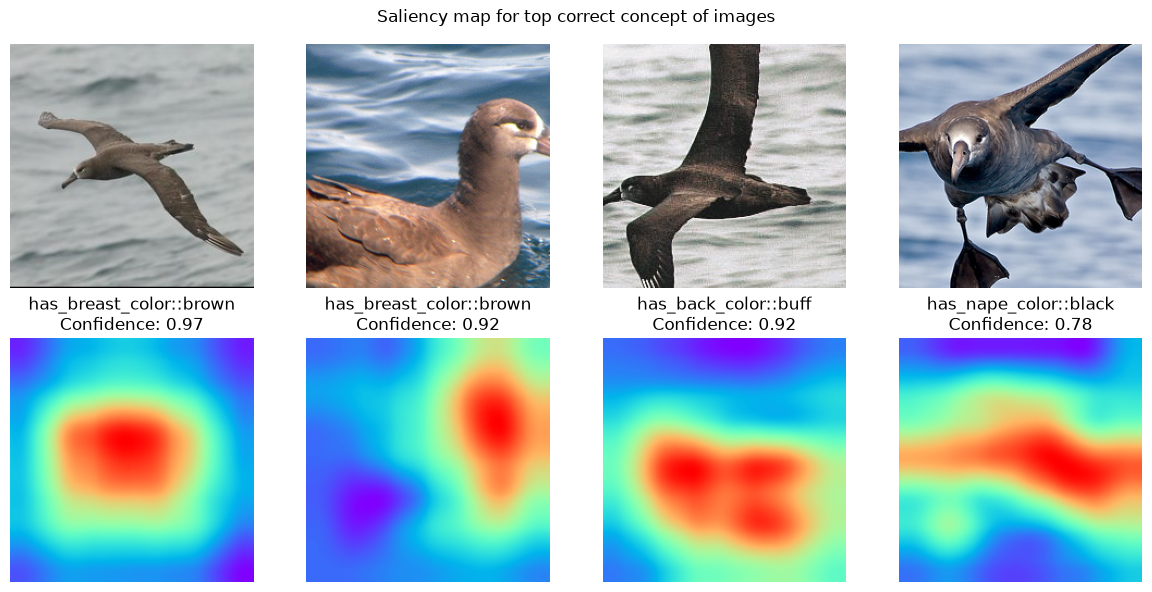


🧬 Synthesizing models from 1 spec result(s)...

🎉 Synthesis Complete:
   Total specs: 48
   Wrapped models: 2


In [ ]:
# Wrap bottleneck model in ACT fuzzer
from matplotlib import pyplot as plt

from act.front_end.concept.input_spec import ConceptInputSpec
from act.front_end.model_synthesis import synthesize_models_from_specs
from act.front_end.specs import InputSpec, OutputSpec


EPS = [0.01, 0.03, 0.05, 0.1]

INPUT_SHAPE = (1, 3, 224, 224)
RAINBOW_MAP = plt.get_cmap("rainbow")

new_spec_pairs: list[tuple[InputSpec, OutputSpec]] = []

for index, labeled_tensor in enumerate(labeled_tensors):
    input_specs = []

    for eps in EPS:
        input_spec = ConceptInputSpec(
            image=labeled_tensor.tensor,
            saliency_map=norm_maps[index].unsqueeze(0),
            eps=eps
        )

        input_specs.append(input_spec)

    assert labeled_tensor.label is not None
    output_specs = spec_creator._generate_output_specs_for_label(labeled_tensor.label)

    new_spec_pairs.extend([(i, o) for i in input_specs for o in output_specs])

## Display input images and their saliency maps

last_fig, last_axs = plt.subplots(2, NUM_SAMPLES, figsize=(3 * NUM_SAMPLES, 6))

for sample_idx in range(NUM_SAMPLES):
    # Display ground image
    ground_image = ground_images[sample_idx]
    permuted_ground = ground_image.permute(1, 2, 0)
    
    last_axs[0, sample_idx].imshow(permuted_ground.cpu().numpy())
    last_axs[0, sample_idx].axis("off")

    # Top concept name
    sample_concept_index: int = top_concept_index[sample_idx].item() # type: ignore
    sample_concept_name = SLCBM_CUB_ATTRIBUTES[sample_concept_index]
    confidence = concept_probs[sample_idx, sample_concept_index].item()
    last_axs[1, sample_idx].set_title(f"{sample_concept_name}\nConfidence: {confidence:.2f}")

    # Display saliency map as heat map
    norm_map = norm_maps[sample_idx].mean(0).squeeze()
    heatmap = RAINBOW_MAP(norm_map.cpu().numpy())[:, :, :3]
    
    last_axs[1, sample_idx].imshow(heatmap)
    last_axs[1, sample_idx].axis("off")

plt.suptitle("Saliency map for top correct concept of images")
plt.tight_layout()
plt.show()

new_spec = (data_source, model_name, pytorch_model, labeled_tensors, new_spec_pairs)
synth_models = synthesize_models_from_specs([new_spec])

In [7]:
# ACT fuzzing config
from act.front_end.spec_creator_base import LabeledInputTensor
from act.front_end.verifiable_model import InputLayer, InputSpecLayer, VerifiableModel
from act.pipeline.fuzzing.actfuzzer import ACTFuzzer, FuzzingConfig


config_path = Path(ACT_ROOT) / "act/config/pipeline.yaml"
config = FuzzingConfig.from_yaml(
    config_path=config_path,
    max_iterations=256,
    timeout_seconds=60.0,
    report_interval=16,
    verbose=1,
    # Use `adaptive_perdim`
    perturb_mode="adaptive_perdim",
    # Tracing: capture execution traces for analysis
    trace_level=1,
    trace_storage='json')

all_fuzzers = []

# Metadata for instances
instance_info = []

synth_batch_sizes: list[int] = []
synth_seeds: list[list[LabeledInputTensor]] = []

# Iterate over wrapped models for fuzzing results
for idx, item in enumerate(synth_models.items()):
    model: VerifiableModel = item[1] # type: ignore

    input_layer: InputLayer = model.input_layer
    labeled_input = input_layer.labeled_input

    input_spec_layer: InputSpecLayer = model.input_spec
    input_spec = input_spec_layer.spec

    assert labeled_input.label is not None

    images = labeled_input.tensor.to(DEVICE)
    labels = labeled_input.label.to(DEVICE)

    # ACT now combines models, thus we need to infer the new batch size of that
    # synthesised model and change seeds (which expect only one class label) accordingly
    batch_size = images.shape[0]

    initial_seeds = [
        LabeledInputTensor(tensor=images[i:i+1], label=labels[i:i+1])
        for i in range(batch_size)
    ]

    synth_batch_sizes.append(batch_size)
    synth_seeds.append(initial_seeds)

    # We are working with `BOX` input specs generated from `scale_by_concept`,
    # these assertions must hold
    assert input_spec.lb is not None
    assert input_spec.ub is not None

    epsilon = float((input_spec.ub - input_spec.lb).max())

    fuzzer = ACTFuzzer(
        wrapped_model=model,
        initial_seeds=initial_seeds,
        config=config
    )

    # Store instance info for visualization
    instance_info.append({
        'index': idx,
        'input_tensor': labeled_input.tensor,
        'true_label': labeled_input.label,
        'epsilon': epsilon,
        'input_spec': input_spec
    })
    
    fuzzer.fuzz()
    all_fuzzers.append(fuzzer)

AssertionError: Initial corpus must preserve exactly one seed slot per synthesized spec row: corpus=32, specs=96

In [ ]:
# Generate report from traces
from act.pipeline.fuzzing.trace_reader import TraceAnalyzer


trace_files = []

for fuzzer in all_fuzzers:
    if fuzzer.tracer is not None:
        trace_path = fuzzer.tracer.output_path

        if trace_path.exists():
            trace_files.append(trace_path)
            print(f"Found trace file: {trace_path}")

if len(trace_files) > 0:
    for index, file in enumerate(trace_files):
        # Summary plot
        analyzer = TraceAnalyzer(file)

        try:
            analyzer.plot_overview()
        except Exception as e:
            print(f"Could not generate plots: {e}")

        # Plot last `NUM_SAMPLES`
        traces = analyzer.traces

        fig, axs = plt.subplots(3, NUM_SAMPLES, figsize=(NUM_SAMPLES * 3, 9))

        axs[0, 0].set_ylabel("Before fuzzing")
        axs[1, 0].set_ylabel("After fuzzing")
        axs[2, 0].set_ylabel("Difference heatmap")
        
        for sample in range(NUM_SAMPLES):
            trace = traces[-(NUM_SAMPLES - sample)]

            input_before: torch.Tensor = trace["input_before"].squeeze().permute(1, 2, 0)

            axs[0, sample].imshow(input_before.cpu().numpy())

            input_after: torch.Tensor = trace["input_after"].squeeze().permute(1, 2, 0)

            axs[1, sample].imshow(input_after.cpu().numpy())

            difference = torch.norm(input_after - input_before, dim=2)
            difference /= difference.max() + 1e-8
            heatmap = RAINBOW_MAP(difference.cpu().numpy())[:, :, :3]
    
            axs[2, sample].imshow(heatmap)

        plt.suptitle("Fuzzed image areas based on concepts")
        plt.tight_layout()
        plt.show()